# 03 客户流失预警模型

**业务问题**：在客户真正流失**之前**识别出他们，让挽留券花在刀刃上。

## 时点切割（防数据泄漏的核心设计）

```
2009-12-01 ──────────────── 2011-09-10 ─────── 2011-12-09
        特征窗口（只从这里造特征）      预测窗口（只用来生成标签）
                              T_cut = 数据末日 - 90 天
```

- **特征**：仅用 `InvoiceDate ≤ T_cut` 的交易计算（⚠️ 不复用 02 的全周期 RFM——那是用未来预测过去）
- **标签**：`T_cut` 之后 90 天内是否再购买（1 = 复购，0 = 流失）
- **建模客群**：T_cut 前 180 天内有购买的"活跃客户"——挽留只对近期活跃的人有意义，沉睡已久的人是"召回"问题不是"预警"问题

## 模型递进

1. **规则基线**：按 Recency 排序（最朴素的"多久没买就该挽留"直觉）
2. **逻辑回归**（statsmodels）：系数 + 95% 置信区间 + 优势比——统计可解释
3. **XGBoost**：非线性 + 交互，配 SHAP 解释

## 评估：不止 AUC

- AUC / PR-AUC
- **固定预算召回率**：挽留预算只够覆盖 10% 客户时，能抓住多少真流失者（业务真正关心的指标）
- 十分位提升度（lift）
- 训练/测试 AUC 对比（检查过拟合）

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
CLEAN = ROOT / "data" / "clean"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

tx = pd.read_parquet(CLEAN / "transactions.parquet")
ret = pd.read_parquet(CLEAN / "returns.parquet")
tx = tx[tx["has_customer"]].copy()
tx["Amount"] = tx["Quantity"] * tx["Price"]

T_MAX = tx["InvoiceDate"].max()
T_CUT = T_MAX - pd.Timedelta(days=90)
print(f"特征窗口：{tx['InvoiceDate'].min().date()} ~ {T_CUT.date()}；预测窗口：{T_CUT.date()} ~ {T_MAX.date()}（90 天）")

特征窗口：2009-12-01 ~ 2011-09-10；预测窗口：2011-09-10 ~ 2011-12-09（90 天）


In [2]:
hist = tx[tx["InvoiceDate"] <= T_CUT]
fut_ids = set(tx.loc[tx["InvoiceDate"] > T_CUT, "Customer_ID"])

g = hist.groupby("Customer_ID")
feat = pd.DataFrame({
    "last_date": g["InvoiceDate"].max(),
    "first_date": g["InvoiceDate"].min(),
    "frequency": g["Invoice"].nunique(),
    "monetary": g["Amount"].sum(),
    "n_products": g["StockCode"].nunique(),
})
feat["recency"] = (T_CUT - feat["last_date"]).dt.days
feat["tenure"] = (feat["last_date"] - feat["first_date"]).dt.days
feat["aov"] = feat["monetary"] / feat["frequency"]

# 退货率（截至 T_cut）
r = ret[ret["InvoiceDate"] <= T_CUT]
returned = r.groupby("Customer_ID")["Quantity"].sum().abs()
bought = hist.groupby("Customer_ID")["Quantity"].sum()
feat["return_rate"] = (returned / bought).fillna(0).clip(0, 1)

# 动量：近 90 天订单数 vs 前 90 天
q_recent = hist[hist["InvoiceDate"] > T_CUT - pd.Timedelta(days=90)].groupby("Customer_ID")["Invoice"].nunique()
q_prev = hist[(hist["InvoiceDate"] > T_CUT - pd.Timedelta(days=180)) & (hist["InvoiceDate"] <= T_CUT - pd.Timedelta(days=90))].groupby("Customer_ID")["Invoice"].nunique()
feat["orders_last90"] = q_recent.reindex(feat.index).fillna(0)
feat["momentum"] = (q_recent.reindex(feat.index).fillna(0) - q_prev.reindex(feat.index).fillna(0)) / (q_recent.reindex(feat.index).fillna(0) + q_prev.reindex(feat.index).fillna(0) + 1)

# 长尾特征取对数
feat["log_monetary"] = np.log1p(feat["monetary"])
feat["log_aov"] = np.log1p(feat["aov"])

cohort = feat[feat["recency"] <= 180].copy()  # 活跃客群：T_cut 前 180 天内有购买
cohort["repurchase"] = cohort.index.isin(fut_ids).astype(int)  # 1=90天内复购, 0=流失
print(f"建模客群 {len(cohort):,} 人（活跃客户），其中 90 天内流失 {int((cohort['repurchase'] == 0).sum()):,} 人（{(cohort['repurchase'] == 0).mean():.1%}）")

建模客群 2,788 人（活跃客户），其中 90 天内流失 1,065 人（38.2%）


In [3]:
FEATURES = ["recency", "tenure", "frequency", "log_monetary", "log_aov",
            "n_products", "return_rate", "orders_last90", "momentum"]

from sklearn.model_selection import train_test_split

X = cohort[FEATURES]
y = cohort["repurchase"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"train {len(X_train):,} / test {len(X_test):,}，测试集流失率 {(y_test == 0).mean():.1%}")
X[FEATURES].describe().round(2)

train 2,091 / test 697，测试集流失率 38.2%


,recency,tenure,frequency,log_monetary,log_aov,n_products,return_rate,orders_last90,momentum
count,2788.00,2788.00,2788.00,2788.00,2788.00,2788.00,2788.00,2788.00,2788.00
mean,65.67,338.20,8.59,7.29,5.71,103.46,0.02,1.42,-0.02
std,51.80,219.30,14.71,1.34,0.69,130.02,0.07,2.28,0.46
min,0.00,0.00,1.00,1.36,1.36,1.00,0.00,0.00,-0.88
25%,19.00,122.75,2.00,6.40,5.28,28.00,0.00,0.00,-0.50
50%,53.00,388.50,5.00,7.30,5.72,65.00,0.00,1.00,0.00
75%,105.00,530.00,10.00,8.17,6.09,135.00,0.01,2.00,0.50
max,180.00,646.00,309.00,13.03,9.61,2182.00,1.00,46.00,0.86


## 基线：按 Recency 排序

运营的朴素直觉："越久没买的人越可能流失"。它就是所有模型必须打败的及格线。

In [4]:
def budget_recall2(y_churn, score, frac):
    """固定预算召回率：只挽留评分最危险的 frac 比例客户时，抓住的真流失者占比。
    y_churn: 流失标签（1=流失）；score: 越大越像流失。"""
    order = np.argsort(-np.asarray(score))
    n = max(1, int(len(order) * frac))
    return (np.asarray(y_churn)[order[:n]] == 1).sum() / (np.asarray(y_churn) == 1).sum()

from sklearn.metrics import average_precision_score, roc_auc_score

base_score = X_test["recency"].values  # recency 越大越可能流失
print(f"基线 AUC：{roc_auc_score(1 - y_test.values, base_score):.3f}（以流失为正类）")

基线 AUC：0.682（以流失为正类）


## 模型 2：逻辑回归（statsmodels）

特征标准化后拟合，报告**优势比 OR + 95% 置信区间**——置信区间不跨 1 才算显著，这是统计出身讲模型的正确姿势。

In [5]:
import statsmodels.api as sm

mu, sigma = X_train.mean(), X_train.std()
Z_train = (X_train - mu) / sigma
Z_test = (X_test - mu) / sigma

logit = sm.Logit(y_train, sm.add_constant(Z_train)).fit(disp=0)
p_logit = logit.predict(sm.add_constant(Z_test))

or_table = np.exp(logit.conf_int())
or_table["OR"] = np.exp(logit.params)
or_table.columns = ["2.5%", "97.5%", "OR"]
or_table.round(3).sort_values("OR", ascending=False)

,2.5%,97.5%,OR
log_monetary,2.321,5.797,3.668
const,1.807,2.354,2.063
orders_last90,1.034,2.406,1.577
n_products,1.192,1.890,1.501
frequency,0.542,1.829,0.996
return_rate,0.888,1.073,0.976
momentum,0.719,1.011,0.853
recency,0.641,0.886,0.754
log_aov,0.477,0.779,0.610
tenure,0.495,0.735,0.603


In [6]:
print(f"Pseudo R² = {logit.prsquared:.3f} | Log-Likelihood = {logit.llf:.1f} | 样本量 = {int(logit.nobs):,}")
sig = logit.pvalues[logit.pvalues < 0.05]
print(f"\np < 0.05 的显著特征（{len(sig)}/{len(FEATURES)}）：")
print(", ".join(sig.index))

Pseudo R² = 0.162 | Log-Likelihood = -1165.4 | 样本量 = 2,091

p < 0.05 的显著特征（7/9）：
const, recency, tenure, log_monetary, log_aov, n_products, orders_last90


## 模型 3：XGBoost + 三模型对比

In [7]:
import xgboost as xgb

clf = xgb.XGBClassifier(
    n_estimators=150, max_depth=3, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    reg_lambda=2.0, eval_metric="logloss", random_state=42,
)
clf.fit(X_train, y_train)
p_xgb_train = clf.predict_proba(X_train)[:, 1]
p_xgb = clf.predict_proba(X_test)[:, 1]
gap = roc_auc_score(y_train, p_xgb_train) - roc_auc_score(y_test, p_xgb)
print(f"XGB 训练 AUC {roc_auc_score(y_train, p_xgb_train):.3f} / 测试 AUC {roc_auc_score(y_test, p_xgb):.3f}（差距 {gap:.3f}，浅树+正则缓解过拟合）")

XGB 训练 AUC 0.864 / 测试 AUC 0.757（差距 0.108，浅树+正则缓解过拟合）


In [8]:
# 统一方向：流失为正类（1-churn），三个模型的"流失评分"
s_base = X_test["recency"].values
s_logit = 1 - p_logit.values
s_xgb = 1 - p_xgb

rows = []
for name, s in [("基线(Recency)", s_base), ("逻辑回归", s_logit), ("XGBoost", s_xgb)]:
    churn = 1 - y_test.values
    rows.append({
        "模型": name,
        "AUC": roc_auc_score(churn, s),
        "PR-AUC": average_precision_score(churn, s),
        "预算10%召回": budget_recall2(churn, s, 0.10),
        "预算20%召回": budget_recall2(churn, s, 0.20),
    })
cmp = pd.DataFrame(rows).round(3)
print(cmp.to_string(index=False))

         模型   AUC  PR-AUC  预算10%召回  预算20%召回
基线(Recency) 0.682   0.556    0.165    0.335
       逻辑回归 0.758   0.625    0.184    0.350
    XGBoost 0.757   0.632    0.184    0.380


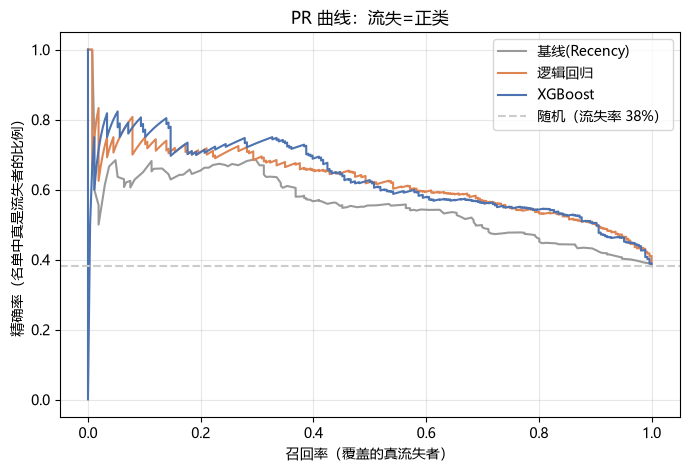

In [9]:
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(8, 5))
for name, s, c in [("基线(Recency)", s_base, "#999999"), ("逻辑回归", s_logit, "#DD8452"), ("XGBoost", s_xgb, "#4C72B0")]:
    prec, recv, _ = precision_recall_curve(1 - y_test.values, s)
    ax.plot(recv, prec, label=name, color=c)
ax.axhline((y_test == 0).mean(), ls="--", color="#cccccc", label=f"随机（流失率 {(y_test == 0).mean():.0%}）")
ax.set_xlabel("召回率（覆盖的真流失者）")
ax.set_ylabel("精确率（名单中真是流失者的比例）")
ax.set_title("PR 曲线：流失=正类")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG / "08_pr_curve.png", dpi=120, bbox_inches="tight")
plt.show()

## 十分位提升度 + SHAP 解释

In [10]:
dec = pd.DataFrame({"score": s_xgb, "churn": 1 - y_test.values}).sort_values("score", ascending=False)
dec["decile"] = pd.qcut(np.arange(len(dec)), 10, labels=range(1, 11))
lift = dec.groupby("decile", observed=True)["churn"].agg(["size", "sum", "mean"])
lift.columns = ["人数", "其中流失", "流失率"]
lift["提升度"] = lift["流失率"] / (1 - y_test.values).mean()
lift.round(2)

,人数,其中流失,流失率,提升度
decile,,,,
1,70,49,0.70,1.83
2,70,53,0.76,1.98
3,69,28,0.41,1.06
4,70,31,0.44,1.16
5,70,32,0.46,1.20
6,69,29,0.42,1.10
7,70,19,0.27,0.71
8,69,12,0.17,0.46
9,70,10,0.14,0.37


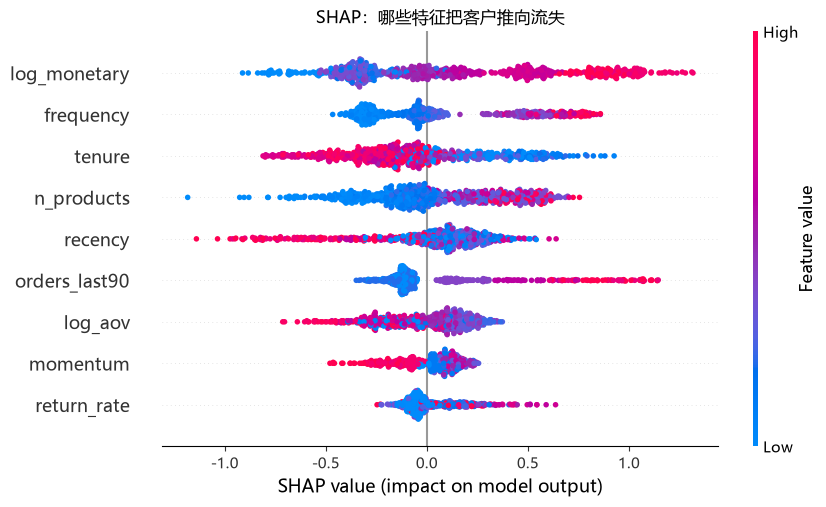

特征重要性（平均|SHAP|）：
log_monetary     0.439
frequency        0.294
tenure           0.276
n_products       0.271
recency          0.227
orders_last90    0.221
log_aov          0.172
momentum         0.120
return_rate      0.097


In [11]:
import shap

explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(X_test)

fig = plt.figure()
shap.summary_plot(sv, X_test, show=False)
plt.gcf().set_size_inches(9, 5)
plt.title("SHAP：哪些特征把客户推向流失")
plt.gcf().savefig(FIG / "09_shap.png", dpi=120, bbox_inches="tight")
plt.show()

imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("特征重要性（平均|SHAP|）：")
print(imp.round(3).to_string())

In [12]:
# 全量活跃客群打分，存给 W4 做投放名单与 ROI
cohort["churn_score"] = clf.predict_proba(cohort[FEATURES])[:, 0]
cohort[["churn_score", "repurchase", "recency", "frequency", "log_monetary"]].reset_index().to_parquet(
    CLEAN / "churn_scores.parquet", index=False
)
n10 = int(len(cohort) * 0.10)
top10 = cohort.nlargest(n10, "churn_score")
gmv_risk = np.expm1(top10["log_monetary"]).sum()
print(f"已保存 churn_scores.parquet")
print(f"若预算只够覆盖 10%（{n10} 人），模型选出的名单历史 90 天贡献销售额 £{gmv_risk:,.0f}")

已保存 churn_scores.parquet
若预算只够覆盖 10%（278 人），模型选出的名单历史 90 天贡献销售额 £153,979


## 结论（2026-11-05 执行）

**建模设定**：2,788 位活跃客户（T_cut 前 180 天内有购买），90 天流失率 38.2%；特征仅用 2011-09-10 之前的数据，杜绝泄漏。

**三个核心结论：**

1. **模型显著优于"拍脑袋"**：逻辑回归/XGBoost AUC 0.758/0.757 vs 基线（仅按"多久没买"排序）0.682；预测最危险的 20% 客户可覆盖 38.0% 的真流失者（基线 33.5%），Top 20% 名单流失率 70-76%，是基线流失率的 ~1.9 倍。

2. **这份数据里，逻辑回归几乎追平 XGBoost**（0.758 vs 0.757）——客户行为特征与流失的关系接近单调线性，此时**可解释性比复杂模型更值钱**：逻辑回归给出带置信区间的作用方向，运营能直接理解。XGBoost 仅在预算 20% 的召回上有小幅优势（38.0% vs 35.0%）。面试标准追问："为什么不用深度学习？"——答案就在这。

3. **谁在流失（OR，7/9 特征显著，Pseudo R²=0.162）**：花钱越多（OR 3.67）、买过的品类越宽（1.50）、近 90 天订单越多（1.58）→ 越不容易流失；**客单价越高（0.61）、资历越老（0.60）反而越危险**——批发型大单客户天然低频，不能按"很久没买"误判成流失，这是运营名单上必须排除的陷阱。

**交付物**：`churn_scores.parquet`——全量活跃客群的流失评分。若挽留预算只覆盖 10%（278 人），模型选出的名单 90 天历史销售额 £15.4 万，这就是 W4 里 A/B 实验与 ROI 测算的投放名单。